# How are in-demand skills trending for Data Analysts?

**Methodology**

1. Aggregate skills count monthly
2. Re-analyze based on percentage of total jobs
3. Plot trending of skills throught 2025 for Data Analyst

### Import Libraries and Data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
import seaborn as sns
import ast

dataset = load_dataset("lukebarousse/data_jobs")
df = dataset['train'].to_pandas()
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

### Group Skills by Month & Convert to Percent Formatter

In [2]:
#Filter out job title to Data Analyst and job country in the US
df_DA = df[(df['job_title'] == 'Data Analyst') & (df['job_country'] == 'United States')].explode('job_skills')
df_DA

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
36,Data Analyst,Data Analyst,"Des Moines, IA",via Trabajo.org,Full-time,False,"Illinois, United States",2023-11-06 13:01:22,False,True,United States,NaN,NaN,NaN,Assuredpartners,NaN,NaN
155,Data Analyst,Data Analyst,"Tampa, FL",via LinkedIn,Full-time,False,"Florida, United States",2023-01-19 13:19:45,False,False,United States,NaN,NaN,NaN,Citi,sql,"{'analyst_tools': ['excel'], 'async': ['jira']..."
155,Data Analyst,Data Analyst,"Tampa, FL",via LinkedIn,Full-time,False,"Florida, United States",2023-01-19 13:19:45,False,False,United States,NaN,NaN,NaN,Citi,python,"{'analyst_tools': ['excel'], 'async': ['jira']..."
155,Data Analyst,Data Analyst,"Tampa, FL",via LinkedIn,Full-time,False,"Florida, United States",2023-01-19 13:19:45,False,False,United States,NaN,NaN,NaN,Citi,unix,"{'analyst_tools': ['excel'], 'async': ['jira']..."
155,Data Analyst,Data Analyst,"Tampa, FL",via LinkedIn,Full-time,False,"Florida, United States",2023-01-19 13:19:45,False,False,United States,NaN,NaN,NaN,Citi,excel,"{'analyst_tools': ['excel'], 'async': ['jira']..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785539,Data Analyst,Data Analyst,"Fairfax Station, VA",via Monster,Full-time,False,"New York, United States",2023-01-06 05:59:59,False,True,United States,NaN,NaN,NaN,Guidehouse,databricks,"{'analyst_tools': ['tableau', 'excel'], 'cloud..."
785539,Data Analyst,Data Analyst,"Fairfax Station, VA",via Monster,Full-time,False,"New York, United States",2023-01-06 05:59:59,False,True,United States,NaN,NaN,NaN,Guidehouse,tableau,"{'analyst_tools': ['tableau', 'excel'], 'cloud..."
785539,Data Analyst,Data Analyst,"Fairfax Station, VA",via Monster,Full-time,False,"New York, United States",2023-01-06 05:59:59,False,True,United States,NaN,NaN,NaN,Guidehouse,excel,"{'analyst_tools': ['tableau', 'excel'], 'cloud..."
785685,Data Analyst,Data Analyst,"Indianapolis, IN",via Trabajo.org,Full-time,False,"Illinois, United States",2023-07-16 06:01:27,True,False,United States,NaN,NaN,NaN,"Aara Technologies, Inc",sql,"{'analyst_tools': ['excel'], 'programming': ['..."


In [3]:
#Create new month_nu to aggregate skills
df_DA['month_nu'] = df_DA['job_posted_date'].dt.month

In [4]:
import datetime as dt
#Pivot table with month_nu index and job_skills column by size function
df_skill = df_DA.pivot_table(index = 'month_nu', columns = 'job_skills',  aggfunc='size', fill_value = 0)

#Choosing top demanded skills for Data Analysts
df_skill.loc['total'] = df_skill.sum()
df_DAskill = df_skill[df_skill.loc['total'].sort_values(ascending = False).index]
df_DAskill = df_DAskill.drop('total')
df_DAfinal = df_DAskill.iloc[:, :5]

df_DAfinal

job_skills,sql,excel,tableau,python,power bi
month_nu,,,,,
1,1138,781,646,529,326
2,782,544,408,378,302
3,802,580,463,400,277
4,845,577,462,421,292
5,706,490,367,336,251
6,742,491,395,396,272
7,560,431,296,292,190
8,784,641,480,460,292
9,485,336,277,253,183


In [ ]:
#Count the number of total skills in every month 
df_month = df_DA.groupby(['month_nu']).size()
df_month

month_nu
1     7291
2     5231
3     5472
4     5656
5     4555
6     4923
7     3821
8     5614
9     3277
10    3624
11    2978
12    3278
dtype: int64

In [ ]:
#Modify skill count into percentage of skill in monthly total skills
df_percent = df_DAfinal.div(df_month/100, axis = 0)
df_percent.reset_index(inplace = True)

#Order rows by real month
df_percent['Month'] = df_percent['month_nu'].apply(lambda x: pd.to_datetime(x, format='%m').strftime('%b'))
df_percent.set_index('Month', inplace = True)
df_percent.drop(columns = 'month_nu', inplace = True)
df_percent

job_skills,sql,excel,tableau,python,power bi
Month,,,,,
Jan,15.608284,10.711837,8.860239,7.255521,4.471266
Feb,14.949340,10.399541,7.799656,7.226152,5.773275
Mar,14.656433,10.599415,8.461257,7.309942,5.062135
Apr,14.939887,10.201556,8.168317,7.443423,5.162659
May,15.499451,10.757409,8.057080,7.376509,5.510428
Jun,15.072111,9.973593,8.023563,8.043876,5.525086
Jul,14.655849,11.279770,7.746663,7.641979,4.972520
Aug,13.965087,11.417884,8.550053,8.193801,5.201283
Sep,14.800122,10.253280,8.452853,7.720476,5.584376


### Plot trending of skills

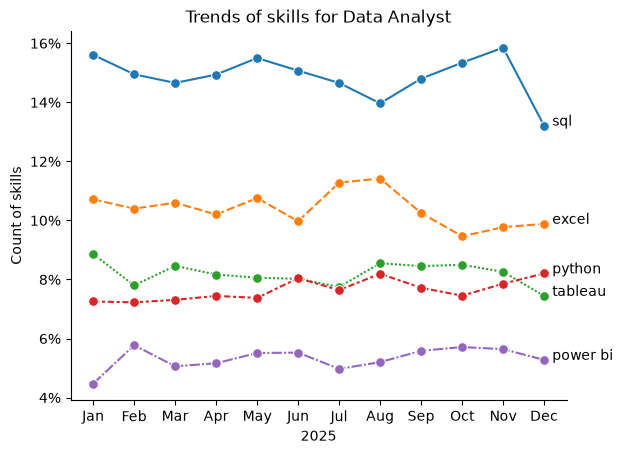

In [12]:

sns.lineplot(data = df_percent, linestyle = '--', marker = 'o', markersize=7, palette = 'tab10')
sns.despine()

#Set labels and title of graph
plt.title('Trends of skills for Data Analyst')
plt.ylabel('Count of skills')
plt.xlabel('2025')

#Remove note
plt.legend().remove()

#Add percent symbol
from matplotlib.ticker import PercentFormatter
ax = plt.gca()
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
for i in range(5):
    plt.text(11.2, df_percent.iloc[-1, i], df_percent.columns[i])

plt.show()